# Лабораторная работа 1. Задача классификации

**Цель работы:** реализовать алгоритмы бинарной классификации «с нуля» на NumPy, применить их к реальному датасету и сравнить с эталонными реализациями из scikit-learn.

**Как работать с ноутбуком**

- В ячейке конфигурации (раздел 1) укажите номер задачи (зависит от группы) и номер варианта (зависит от списка).
- Ячейки с `raise NotImplementedError` или `# TODO` — ваша работа. Остальные ячейки менять не нужно.
- Алгоритмы пишутся **только на NumPy**. Pandas — для загрузки и подготовки данных, matplotlib/seaborn — для графиков. scikit-learn разрешён только в ячейках проверки и в сравнении с эталоном.
- После каждого блока стоит тест. Не переходите дальше, пока он не пройден.
- Работа принимается, если выполнены критерии из раздела 10 (качество не ниже заданного порога и не хуже эталона sklearn).
- Разрабатывайте на подвыборке (`USE_FULL_DATA = False`), финальный прогон делайте на полных данных.
- Циклов по объектам выборки в `predict` и в основных вычислениях быть не должно: используйте векторизацию.

**Задания**

1. Проанализировать датасет, привести его к числовому виду, построить корреляционную матрицу, предложить способы расширения данных.
2. Реализовать метрики качества и два классификатора: метод вашего варианта и нейронную сеть прямого распространения (MLP).
3. Подобрать гиперпараметры, обосновать выбор.
4. Оценить качество на тестовой выборке, сравнить с scikit-learn, проанализировать ошибочно классифицированные объекты.
5. Улучшить результат (обработка данных, порог, баланс классов, параметры) и сделать выводы.

**Задачи (датасеты)**

| № | Задача | Источник |
|---|--------|----------|
| 1 | Сердечно-сосудистые заболевания | [Kaggle](https://www.kaggle.com/datasets/kamilpytlak/personal-key-indicators-of-heart-disease) |
| 2 | Качество воды | [Kaggle](https://www.kaggle.com/datasets/adityakadiwal/water-potability) |
| 3 | Стартапы | [Kaggle](https://www.kaggle.com/datasets/manishkc06/startup-success-prediction) |
| 4 | Задержка рейса | [Kaggle](https://www.kaggle.com/datasets/threnjen/2019-airline-delays-and-cancellations) |
| 5 | Вредоносные сайты | [Kaggle](https://www.kaggle.com/xwolf12/malicious-and-benign-websites) |

**Варианты**

| № варианта | Метод вашего варианта | Вторая модель |
|---|---|---|
| 1 | Наивный байесовский классификатор (гауссов) | MLP |
| 2 | Метод опорных векторов (линейный) | MLP |
| 3 | Решающее дерево | MLP |
| 4 | k ближайших соседей | MLP |
| 5 | Случайный лес (нужно реализовать и решающее дерево) — **для самостоятельного разбора** | MLP |
| 6 | Логистическая регрессия — **для самостоятельного разбора** | MLP |

Методы вариантов 5 и 6 не разбирались на занятиях: теорию изучите самостоятельно по учебным материалам.

### 1. Подготовка окружения

#### 1.1. Импорт библиотек

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
pd.set_option("display.max_columns", 50)

#### 1.2. Конфигурация

Укажите **свои** `TASK` и `VARIANT`. Имена файлов и целевых колонок заданы в словаре `TASKS`: сверьте их с файлами, которые вы скачали, и при необходимости поправьте.

In [2]:
import os

TASK = 2
VARIANT = 3

SEED = 42
DATA_DIR = "data" if os.path.exists("data/water_potability.csv") else "."  # папка с water_potability.csv
USE_FULL_DATA = False
DEV_N = 20_000   # в датасете всего 3276 объектов, поэтому подвыборка фактически не применяется

TASKS = {
    1: dict(name="Сердечно-сосудистые заболевания", file="heart_2020_cleaned.csv", target="HeartDisease", positive="Yes"),
    2: dict(name="Качество воды", file="water_potability.csv", target="Potability", positive=1),
    3: dict(name="Стартапы", file="startup data.csv", target="status", positive="acquired"),
    4: dict(name="Задержка рейса", file="full_data.csv", target="DEP_DEL15", positive=1),
    5: dict(name="Вредоносные сайты", file="dataset.csv", target="Type", positive=1),
}
MIN_AUC = {1: 0.8, 2: 0.65, 3: 0.70, 4: 0.60, 5: 0.85}
ACC_TOL = 0.07
METHODS = {1: "nb", 2: "svm", 3: "dt", 4: "knn", 5: "rf", 6: "logreg"}
METHOD_NAMES = {
    "rf": "Случайный лес", "svm": "SVM", "logreg": "Логистическая регрессия",
    "knn": "kNN", "nb": "Наивный Байес", "dt": "Решающее дерево",
}

cfg = TASKS[TASK]
METHOD = METHODS[VARIANT]
print(f"Задача {TASK}: {cfg['name']}")
print(f"Вариант {VARIANT}: {METHOD_NAMES[METHOD]} + MLP")


def is_mine(*keys):
    if METHOD in keys:
        return True
    print(f"Пропуск: не ваш вариант (ваш метод — {METHOD_NAMES[METHOD]})")
    return False

Задача 2: Качество воды
Вариант 3: Решающее дерево + MLP


#### 1.3. Служебные функции

Готовые функции для разбиения выборки и стандартизации. Они понадобятся дальше, менять их не нужно.

In [3]:
def train_test_split_np(X, y, test_size=0.2, seed=SEED, stratify=True):
    r = np.random.default_rng(seed)
    n = len(y)
    if stratify:
        parts = []
        for c in np.unique(y):
            idx = np.flatnonzero(y == c)
            r.shuffle(idx)
            parts.append(idx[: int(round(len(idx) * test_size))])
        test_idx = np.concatenate(parts)
    else:
        test_idx = r.permutation(n)[: int(round(n * test_size))]
    mask = np.zeros(n, dtype=bool)
    mask[test_idx] = True
    return X[~mask], X[mask], y[~mask], y[mask]


def subsample(X, y, n, seed=SEED):
    if len(y) <= n:
        return X, y
    idx = np.random.default_rng(seed).choice(len(y), size=n, replace=False)
    return X[idx], y[idx]


class Standardizer:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


class BaseClassifier:
    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

### 2. Анализ и подготовка данных (задание 1)

#### 2.1. Загрузка

In [4]:
df = pd.read_csv(f"{DATA_DIR}/{cfg['file']}")
print(df.shape)
df.head()

(3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


#### 2.2. Описание датасета

Выведите размер датасета, список колонок и их типы, число пропусков, статистики (`describe`) и распределение целевой переменной. Ниже в markdown-ячейке опишите, что вы увидели: какие колонки что означают, есть ли пропуски, выбросы, дисбаланс классов.

Размер: (3276, 10)

Колонки и типы:
ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64

Пропуски (шт. и доля):
                 n_missing  share
ph                     491  0.150
Hardness                 0  0.000
Solids                   0  0.000
Chloramines              0  0.000
Sulfate                781  0.238
Conductivity             0  0.000
Organic_carbon           0  0.000
Trihalomethanes        162  0.049
Turbidity                0  0.000
Potability               0  0.000

Дубликаты строк: 0

Распределение целевой переменной:
Potability
0    1998
1    1278
Potability
0    0.61
1    0.39


,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.08,1.59,0.00,6.09,7.04,8.06,14.00
Hardness,3276.0,196.37,32.88,47.43,176.85,196.97,216.67,323.12
Solids,3276.0,22014.09,8768.57,320.94,15666.69,20927.83,27332.76,61227.20
Chloramines,3276.0,7.12,1.58,0.35,6.13,7.13,8.11,13.13
Sulfate,2495.0,333.78,41.42,129.00,307.70,333.07,359.95,481.03
Conductivity,3276.0,426.21,80.82,181.48,365.73,421.88,481.79,753.34
Organic_carbon,3276.0,14.28,3.31,2.20,12.07,14.22,16.56,28.30
Trihalomethanes,3114.0,66.40,16.18,0.74,55.84,66.62,77.34,124.00
Turbidity,3276.0,3.97,0.78,1.45,3.44,3.96,4.50,6.74
Potability,3276.0,0.39,0.49,0.00,0.00,0.00,1.00,1.00


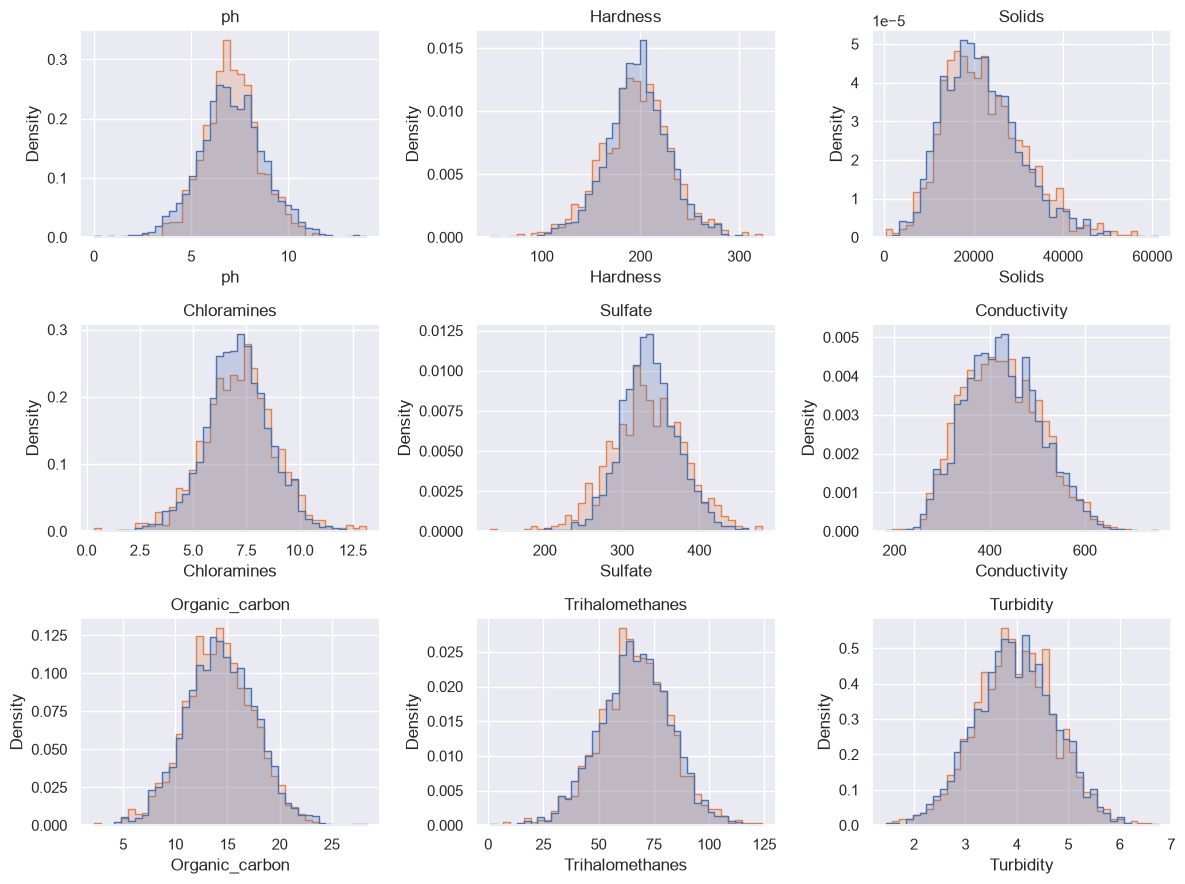

In [5]:
print("Размер:", df.shape)
print()
print("Колонки и типы:")
print(df.dtypes.to_string())
print()
print("Пропуски (шт. и доля):")
miss = pd.DataFrame({"n_missing": df.isna().sum(), "share": (df.isna().mean()).round(3)})
print(miss.to_string())
print()
print("Дубликаты строк:", df.duplicated().sum())
print()
print("Распределение целевой переменной:")
print(df[cfg["target"]].value_counts().to_string())
print(df[cfg["target"]].value_counts(normalize=True).round(3).to_string())
display(df.describe().T.round(2))

fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.ravel(), [c for c in df.columns if c != cfg["target"]]):
    sns.histplot(data=df, x=col, hue=cfg["target"], bins=40, element="step", stat="density",
                 common_norm=False, ax=ax, legend=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Описание датасета:** таблица из 3276 водоёмов/проб (10 колонок, дубликатов нет). Девять признаков — физико-химические показатели воды, все числовые (`float64`): `ph`, `Hardness` (жёсткость), `Solids` (общая минерализация, TDS), `Chloramines`, `Sulfate`, `Conductivity` (электропроводность), `Organic_carbon`, `Trihalomethanes`, `Turbidity` (мутность). Целевая переменная `Potability`: 1 — вода пригодна для питья, 0 — нет.

- **Пропуски:** `ph` — 491 (15,0 %), `Sulfate` — 781 (23,8 %), `Trihalomethanes` — 162 (4,9 %); в остальных колонках пропусков нет.
- **Дисбаланс:** 1998 объектов класса 0 (61 %) и 1278 класса 1 (39 %) — умеренный. Тривиальный ответ «всегда 0» даёт accuracy 0,61, поэтому качество надо мерить по AUC и F1.
- **Выбросы:** у `Solids` длинный правый хвост (медиана ≈ 20 900, максимум ≈ 61 200); `ph` лежит в диапазоне 0–14 (значение 0 встречается у одной пробы — физически экстремально, но оставлено); остальные признаки распределены близко к нормальному.
- **Главное наблюдение:** на гистограммах распределения признаков для классов 0 и 1 почти совпадают — отдельные признаки класс практически не разделяют. Это задаёт потолок качества: задача шумная, ожидать AUC выше ~0,7 не стоит.

#### 2.3. Преобразование к числовому виду

**Приведите все признаки к числовому виду: даты и время, строковые категориальные признаки, пропуски, бинарные Yes/No и т. д.** Нечисловые колонки без смысла для модели (идентификаторы, свободный текст) можно удалить с пояснением.

**На выходе** должны быть три переменные:

- `X` — `np.ndarray` типа `float`, размер `(n_samples, n_features)`;
- `y` — `np.ndarray` из нулей и единиц (1 — положительный класс из `cfg["positive"]`);
- `feature_names` — список имён признаков.

In [6]:
# Все признаки уже числовые (float). Единственная проблема — пропуски в ph, Sulfate, Trihalomethanes.
# Заполняем их медианой столбца (медиана устойчива к выбросам). Дополнительно добавляем бинарные
# индикаторы «значение было пропущено», чтобы модель могла использовать сам факт пропуска.
target = cfg["target"]
feat_cols = [c for c in df.columns if c != target]

df_num = df[feat_cols].copy()
miss_cols = [c for c in feat_cols if df_num[c].isna().any()]
for c in miss_cols:
    df_num[c + "_missing"] = df_num[c].isna().astype(float)
    df_num[c] = df_num[c].fillna(df_num[c].median())

X = df_num.to_numpy(dtype=float)
y = (df[target] == cfg["positive"]).astype(int).to_numpy()
feature_names = list(df_num.columns)
print("Признаки:", feature_names)

Признаки: ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'ph_missing', 'Sulfate_missing', 'Trihalomethanes_missing']


In [7]:
assert isinstance(X, np.ndarray) and X.dtype.kind == "f" and X.ndim == 2, "X должен быть float-массивом (n, k)"
assert not np.isnan(X).any() and not np.isinf(X).any(), "в X остались NaN/inf"
assert isinstance(y, np.ndarray) and set(np.unique(y)) <= {0, 1}, "y должен состоять из 0 и 1"
assert len(X) == len(y), "X и y разной длины"
assert len(feature_names) == X.shape[1], "feature_names не соответствует числу колонок X"
print(f"OK: {X.shape[0]} объектов, {X.shape[1]} признаков, доля положительного класса {y.mean():.3f}")

OK: 3276 объектов, 12 признаков, доля положительного класса 0.390


#### 2.4. Корреляционная матрица

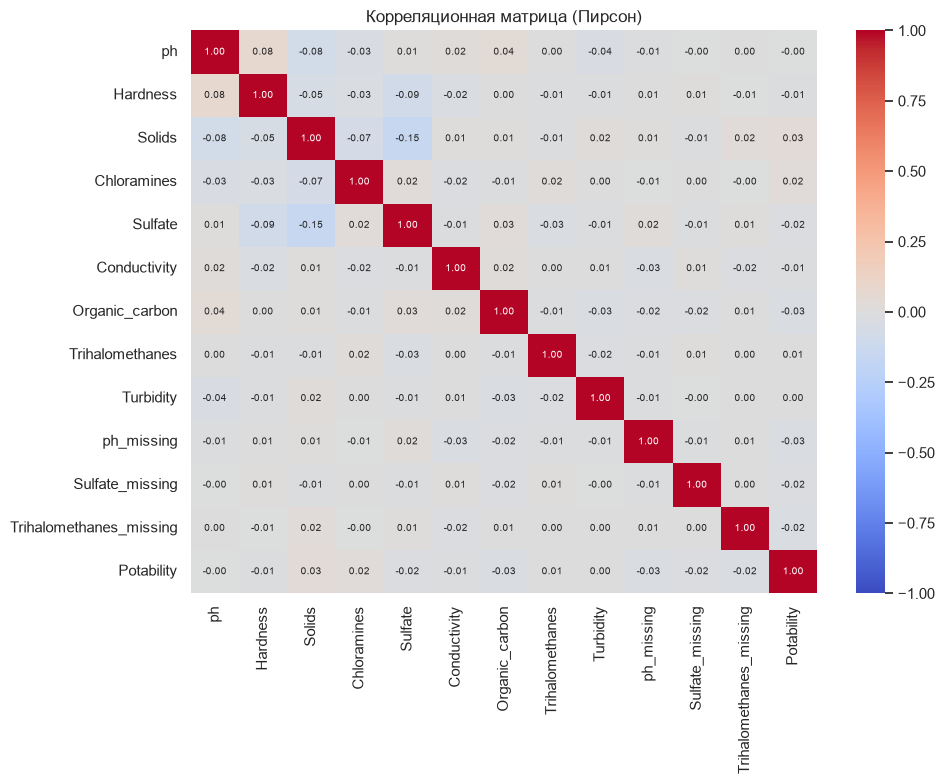

Корреляция признаков с целевой переменной (по модулю):
Solids                     0.034
Organic_carbon            -0.030
ph_missing                -0.025
Chloramines                0.024
Trihalomethanes_missing   -0.024
Sulfate                   -0.020
Sulfate_missing           -0.017
Hardness                  -0.014
Conductivity              -0.008
Trihalomethanes            0.007
ph                        -0.003
Turbidity                  0.002

Самая сильная корреляция между признаками: Solids и Sulfate, |r| = 0.150


In [8]:
corr_df = df_num.assign(**{target: y}).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Корреляционная матрица (Пирсон)")
plt.tight_layout()
plt.show()

print("Корреляция признаков с целевой переменной (по модулю):")
print(corr_df[target].drop(target).sort_values(key=np.abs, ascending=False).round(3).to_string())

# самые сильные корреляции между самими признаками
cm = corr_df.drop(index=target, columns=target).abs().to_numpy().copy()
np.fill_diagonal(cm, 0)
i, j = np.unravel_index(np.argmax(cm), cm.shape)
print(f"\nСамая сильная корреляция между признаками: {feature_names[i]} и {feature_names[j]}, |r| = {cm[i, j]:.3f}")

**Анализ корреляций:** с целевой переменной все признаки связаны очень слабо: максимум |r| = 0,034 (`Solids`), далее `Organic_carbon` (−0,030) и `Chloramines` (0,024); у `ph` и `Turbidity` корреляция практически нулевая. Линейной зависимости «признак → пригодность» в данных нет, поэтому качество нужно ждать от нелинейных моделей (дерево, MLP) и от взаимодействия признаков, а не от отдельных показателей. Между самими признаками тоже нет сильных связей: наибольшая — `Solids`–`Sulfate`, |r| = 0,15, то есть мультиколлинеарности нет и удалять признаки по этой причине не нужно (при |r| > 0,8–0,9 имело бы смысл оставить один из пары или объединить их). Корреляции индикаторов пропусков с целью тоже малы (|r| ≤ 0,025): сам факт пропуска почти не информативен.

*Ковариация и корреляция.* Ковариация $\mathrm{cov}(x,y)=\mathbb{E}[(x-\mu_x)(y-\mu_y)]$ показывает направление совместного изменения, но зависит от масштаба и единиц измерения (`Solids` в десятках тысяч, `Turbidity` в единицах — их ковариации с чем-либо несравнимы). Корреляция Пирсона $r=\mathrm{cov}(x,y)/(\sigma_x\sigma_y)$ — это нормированная ковариация: безразмерная, лежит в $[-1,1]$ и сравнима между парами признаков; при этом она измеряет только *линейную* связь.

**Как расширить датасет:** (1) добавить время и место отбора пробы (сезон, регион, тип источника — скважина, река, водопровод): состав воды сильно зависит от сезона и геологии; (2) измерять больше показателей: нитраты, нитриты, железо, свинец, мышьяк, фториды, микробиологию (колиформные бактерии) — именно они чаще всего определяют непригодность; (3) собрать повторные замеры одного источника и усреднять их, чтобы уменьшить шум; (4) брать разметку из стандартов (СанПиН/ВОЗ), а не из экспертных оценок, чтобы уменьшить ошибки разметки; (5) искусственное расширение: аугментация шумом в пределах погрешности приборов, SMOTE/oversampling для миноритарного класса.

#### 2.5. Разбиение выборки и стандартизация

Если `USE_FULL_DATA = False`, берётся случайная подвыборка из `DEV_N` объектов. Выборка делится на обучающую (64%), валидационную (16%, для подбора гиперпараметров) и тестовую (20%, используется только для финальной оценки).

In [9]:
if not USE_FULL_DATA:
    X, y = subsample(X, y, DEV_N)

X_tr, X_te, y_tr, y_te = train_test_split_np(X, y, test_size=0.2)
X_tr, X_val, y_tr, y_val = train_test_split_np(X_tr, y_tr, test_size=0.2)

scaler = Standardizer().fit(X_tr)
Xs_tr, Xs_val, Xs_te = (scaler.transform(a) for a in (X_tr, X_val, X_te))

print(f"train {Xs_tr.shape}, val {Xs_val.shape}, test {Xs_te.shape}")
print(f"доля положительного класса: train {y_tr.mean():.3f}, val {y_val.mean():.3f}, test {y_te.mean():.3f}")

train (2096, 12), val (524, 12), test (656, 12)
доля положительного класса: train 0.390, val 0.389, test 0.390


### 3. Метрики качества (задание 2, часть 1)

Реализуйте метрики для бинарной классификации. Положительный класс — `1`. Если знаменатель равен нулю, возвращайте `0.0`.

$$\text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN},\quad \text{Accuracy}=\frac{TP+TN}{n},\quad F_1=\frac{2\,P\,R}{P+R}$$

In [10]:
def confusion_matrix_np(y_true, y_pred):
    """Вернуть массив [[TN, FP], [FN, TP]]."""
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])


def accuracy(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_np(y_true, y_pred)
    n = tn + fp + fn + tp
    return float((tp + tn) / n) if n else 0.0


def precision(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_np(y_true, y_pred)
    return float(tp / (tp + fp)) if (tp + fp) else 0.0


def recall(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_np(y_true, y_pred)
    return float(tp / (tp + fn)) if (tp + fn) else 0.0


def f1(y_true, y_pred):
    p, r = precision(y_true, y_pred), recall(y_true, y_pred)
    return float(2 * p * r / (p + r)) if (p + r) else 0.0

In [11]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

r = np.random.default_rng(0)
yt, yp = r.integers(0, 2, 500), r.integers(0, 2, 500)
assert np.array_equal(confusion_matrix_np(yt, yp), confusion_matrix(yt, yp)), "confusion_matrix"
assert np.isclose(accuracy(yt, yp), accuracy_score(yt, yp)), "accuracy"
assert np.isclose(precision(yt, yp), precision_score(yt, yp)), "precision"
assert np.isclose(recall(yt, yp), recall_score(yt, yp)), "recall"
assert np.isclose(f1(yt, yp), f1_score(yt, yp)), "f1"
assert precision(yt, np.zeros(500, dtype=int)) == 0.0, "деление на ноль в precision"
print("Метрики: OK")

Метрики: OK


In [12]:
def report(y_true, y_pred):
    return dict(accuracy=accuracy(y_true, y_pred), precision=precision(y_true, y_pred),
                recall=recall(y_true, y_pred), f1=f1(y_true, y_pred))


def plot_confusion(y_true, y_pred, title="", ax=None):
    sns.heatmap(confusion_matrix_np(y_true, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"], ax=ax)
    (ax or plt.gca()).set_title(title)

### 4. Реализация алгоритмов (задание 2, часть 2)

Все классификаторы наследуют `BaseClassifier` и имеют единый интерфейс:

- `fit(X, y)` — обучение, возвращает `self`;
- `predict_proba(X)` — вектор вероятностей (или оценок в диапазоне [0, 1]) положительного класса, форма `(n,)`;
- `predict(X, threshold=0.5)` — уже реализован в базовом классе.

Реализовывать нужно **метод своего варианта** и **MLP** (раздел 4.8). Остальные разделы пропустите: их тесты выведут «Пропуск».

#### 4.1. Вспомогательные функции и проверочные данные

In [13]:
def sigmoid(z):
    """Устойчивая сигмоида: без переполнения при больших по модулю z."""
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))   # exp от неположительного числа — переполнения нет
    ez = np.exp(z[~pos])                        # exp от отрицательного числа — тоже безопасно
    out[~pos] = ez / (1.0 + ez)
    return out

In [14]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("error")
    z = np.array([-1000.0, -1.0, 0.0, 1.0, 1000.0])
    s = sigmoid(z)
assert np.allclose(s, [0.0, 1 / (1 + np.e), 0.5, np.e / (1 + np.e), 1.0]), "значения сигмоиды"
print("sigmoid: OK")

sigmoid: OK


Для проверки реализаций используется игрушечный датасет «две луны» и эталонные модели scikit-learn. Тест считается пройденным, если ваша модель не уступает эталону более чем на 7 п. п. accuracy.

In [15]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier as SkRF
from sklearn.tree import DecisionTreeClassifier as SkDT
from sklearn.svm import LinearSVC as SkSVC
from sklearn.linear_model import LogisticRegression as SkLR
from sklearn.neighbors import KNeighborsClassifier as SkKNN
from sklearn.naive_bayes import GaussianNB as SkNB
from sklearn.neural_network import MLPClassifier as SkMLP


warnings.filterwarnings("ignore", category=ConvergenceWarning)


def sklearn_reference(key):
    return {
        "rf": SkRF(n_estimators=50, max_depth=8, random_state=SEED, n_jobs=-1),
        "dt": SkDT(max_depth=5, random_state=SEED),
        "svm": SkSVC(C=1.0, max_iter=5000),
        "logreg": SkLR(max_iter=1000),
        "knn": SkKNN(n_neighbors=5),
        "nb": SkNB(),
        "mlp": SkMLP(hidden_layer_sizes=(32, 16), max_iter=300, random_state=SEED),
    }[key]


Xm, ym = make_moons(600, noise=0.25, random_state=0)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split_np(Xm, ym, test_size=0.3, seed=0)


def check_model(model, key, min_acc=0.8, tol=0.07):
    ref = sklearn_reference(key)
    model.fit(Xt_tr, yt_tr)
    ref.fit(Xt_tr, yt_tr)
    proba = model.predict_proba(Xt_te)
    assert proba.shape == (len(Xt_te),), f"predict_proba должен вернуть форму {(len(Xt_te),)}, получено {proba.shape}"
    assert np.all((proba >= 0) & (proba <= 1)), "вероятности вне [0, 1]"
    acc, acc_ref = accuracy(yt_te, model.predict(Xt_te)), ref.score(Xt_te, yt_te)
    assert acc >= min_acc and acc >= acc_ref - tol, f"accuracy {acc:.3f} (sklearn {acc_ref:.3f})"
    print(f"OK: accuracy {acc:.3f} (sklearn {acc_ref:.3f})")
    return model

#### 4.2. Решающее дерево (варианты 3 и 5)

Бинарное дерево с критерием Джини. Для двух классов с долей положительных $p$: $G = 2p(1-p)$. Прирост информации при разбиении:

$$\Delta G = G_{\text{parent}} - \frac{n_L}{n}G_L - \frac{n_R}{n}G_R$$

Требования:

- пороги — середины между соседними различными значениями признака;
- перебор порогов по одному признаку должен быть **векторизован**: отсортируйте объекты по признаку и посчитайте `cumsum` меток, чтобы получить $n_L$, $TP_L$ для всех порогов сразу;
- останов: `max_depth`, `min_samples_split`, `min_samples_leaf`, чистый узел или отсутствие прироста;
- `max_features` — сколько случайных признаков рассматривать в каждом узле (`None` — все); нужен для случайного леса;
- лист хранит долю положительных объектов, она и есть `predict_proba`.

In [16]:
class DecisionTree(BaseClassifier):
    def __init__(self, max_depth=5, min_samples_split=2, min_samples_leaf=1, max_features=None, seed=SEED):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.rng = np.random.default_rng(seed)

    def _gini(self, y):
        if len(y) == 0:
            return 0.0
        p = y.mean()
        return 2.0 * p * (1.0 - p)

    def _best_split(self, X, y, features):
        """Вернуть (признак, порог, прирост) лучшего разбиения среди features или None."""
        n = len(y)
        parent = self._gini(y)
        msl = self.min_samples_leaf
        best = None
        best_gain = 1e-12                      # прирост должен быть строго положительным
        n_left = np.arange(1, n)               # разбиение после i-го объекта: слева i+1 объектов
        n_right = n - n_left
        for f in features:
            order = np.argsort(X[:, f], kind="stable")
            xs, ys = X[order, f], y[order]
            tp_left = np.cumsum(ys)[:-1]       # число положительных слева для всех порогов сразу
            tp_right = ys.sum() - tp_left
            p_l, p_r = tp_left / n_left, tp_right / n_right
            gain = parent - n_left / n * 2 * p_l * (1 - p_l) - n_right / n * 2 * p_r * (1 - p_r)
            # порог допустим, если значения по обе стороны различны и в листьях достаточно объектов
            valid = (xs[1:] != xs[:-1]) & (n_left >= msl) & (n_right >= msl)
            if not valid.any():
                continue
            gain = np.where(valid, gain, -np.inf)
            i = int(np.argmax(gain))
            if gain[i] > best_gain:
                best_gain = gain[i]
                best = (int(f), float((xs[i] + xs[i + 1]) / 2.0), float(gain[i]))
        return best

    def _build(self, X, y, depth):
        """Рекурсивно построить узел (словарь) и вернуть его."""
        node = {"p": float(y.mean())}
        if depth >= self.max_depth or len(y) < self.min_samples_split or node["p"] in (0.0, 1.0):
            return node
        k = X.shape[1]
        if self.max_features is None or self.max_features >= k:
            features = np.arange(k)
        else:
            features = self.rng.choice(k, size=self.max_features, replace=False)
        split = self._best_split(X, y, features)
        if split is None:
            return node
        f, thr, _ = split
        mask = X[:, f] <= thr
        node.update(f=f, thr=thr,
                    left=self._build(X[mask], y[mask], depth + 1),
                    right=self._build(X[~mask], y[~mask], depth + 1))
        return node

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.tree_ = self._build(X, y, 0)
        return self

    def _predict_node(self, node, X, idx, out):
        # рекурсия идёт по узлам дерева, а не по объектам: целые группы объектов уходят в поддеревья масками
        if "f" not in node:
            out[idx] = node["p"]
            return
        go_left = X[idx, node["f"]] <= node["thr"]
        self._predict_node(node["left"], X, idx[go_left], out)
        self._predict_node(node["right"], X, idx[~go_left], out)

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        out = np.zeros(len(X))
        self._predict_node(self.tree_, X, np.arange(len(X)), out)
        return out

In [17]:
if is_mine("dt", "rf"):
    check_model(DecisionTree(max_depth=5), "dt")

OK: accuracy 0.928 (sklearn 0.928)


#### 4.3. Случайный лес (вариант 5, для самостоятельного разбора)

Ансамбль из `n_estimators` деревьев из раздела 4.2 (его тоже нужно реализовать). Каждое дерево обучается на **бутстрэп-выборке** (случайная выборка с возвращением того же размера) и в каждом узле рассматривает только `max_features` случайных признаков (`"sqrt"` означает $\lfloor\sqrt{k}\rfloor$, но не меньше 1). Итоговая вероятность — среднее вероятностей деревьев.

In [18]:
class RandomForest(BaseClassifier):
    def __init__(self, n_estimators=50, max_depth=8, max_features="sqrt", min_samples_leaf=1, seed=SEED):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.max_features = max_features
        self.min_samples_leaf = min_samples_leaf
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [19]:
if is_mine("rf"):
    check_model(RandomForest(n_estimators=30, max_depth=6), "rf")

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.4. Метод опорных векторов (вариант 2)

Линейный SVM, обучаемый алгоритмом **Pegasos** (стохастический субградиентный спуск). Метки переводятся в $\{-1,+1\}$. Минимизируется

$$\frac{\lambda}{2}\lVert w\rVert^2 + \frac{1}{n}\sum_i \max\bigl(0,\;1 - y_i(w^\top x_i + b)\bigr)$$

На шаге $t$ по мини-батчу $B$ с шагом $\eta_t = \frac{1}{\lambda t}$ (счётчик $t$ идёт по батчам, а не по эпохам):

$$w \leftarrow (1-\eta_t\lambda)\,w + \frac{\eta_t}{|B|}\sum_{i\in B_{\text{viol}}} y_i x_i,\qquad b \leftarrow b + \frac{\eta_t}{|B|}\sum_{i\in B_{\text{viol}}} y_i$$

где $B_{\text{viol}}$ — объекты батча с $y_i(w^\top x_i+b)<1$. Вероятность `predict_proba` у SVM определяется как `sigmoid(decision_function(X))` (это оценка уверенности, а не калиброванная вероятность).

In [20]:
class LinearSVM(BaseClassifier):
    def __init__(self, lam=1e-2, n_epochs=20, batch_size=64, seed=SEED):
        self.lam = lam
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        raise NotImplementedError

    def decision_function(self, X):
        raise NotImplementedError

    def predict_proba(self, X):
        return sigmoid(self.decision_function(X))

In [21]:
if is_mine("svm"):
    check_model(LinearSVM(), "svm")

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.5. Логистическая регрессия (вариант 6, для самостоятельного разбора)

$p_i=\sigma(w^\top x_i + b)$. Функция потерь — бинарная кросс-энтропия с L2-регуляризацией, обучение — градиентный спуск по всей выборке:

$$\nabla_w = \frac{1}{n}X^\top(p-y) + \lambda w,\qquad \nabla_b = \frac{1}{n}\sum_i (p_i-y_i)$$

Сохраняйте значение функции потерь на каждой эпохе в `self.loss_history`, это пригодится для графика сходимости.

In [22]:
class LogisticRegression(BaseClassifier):
    def __init__(self, lr=0.5, n_epochs=300, l2=0.0):
        self.lr = lr
        self.n_epochs = n_epochs
        self.l2 = l2

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [23]:
if is_mine("logreg"):
    m = check_model(LogisticRegression(), "logreg")
    assert m.loss_history[-1] < m.loss_history[0], "функция потерь не убывает"
    plt.plot(m.loss_history)
    plt.xlabel("эпоха")
    plt.ylabel("loss")
    plt.show()

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.6. Метод k ближайших соседей (вариант 4)

`fit` запоминает обучающую выборку. `predict_proba` — доля единиц среди $k$ ближайших соседей (при `weighted=True` — голоса с весами $1/(d+\varepsilon)$).

Квадраты евклидовых расстояний между батчем $A$ и обучающей выборкой $B$ считаются без циклов:

$$\lVert a-b\rVert^2 = \lVert a\rVert^2 + \lVert b\rVert^2 - 2\,a^\top b \quad\Rightarrow\quad D^2 = \text{(a²)}[:,\text{None}] + \text{(b²)}[\text{None},:] - 2AB^\top$$

Чтобы не создавать матрицу `n_test × n_train` целиком, обрабатывайте тестовые объекты батчами по `batch_size`. Для $k$ наименьших значений используйте `np.argpartition`, а не полную сортировку. Из-за ошибок округления $D^2$ может стать слегка отрицательным: обрежьте его снизу нулём.

In [24]:
class KNN(BaseClassifier):
    def __init__(self, k=5, batch_size=500, weighted=False):
        self.k = k
        self.batch_size = batch_size
        self.weighted = weighted

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [25]:
if is_mine("knn"):
    check_model(KNN(k=5), "knn")

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.7. Гауссов наивный байесовский классификатор (вариант 1)

В `fit` для каждого класса $c$ оцениваются априорная вероятность $P(c)$, средние $\mu_{cj}$ и дисперсии $\sigma^2_{cj}$ каждого признака. К дисперсиям добавьте `var_smoothing * X.var(axis=0).max()` для устойчивости.

Для объекта $x$ логарифм совместной вероятности:

$$\log P(c) + \sum_j \Bigl[-\tfrac12\log(2\pi\sigma_{cj}^2) - \frac{(x_j-\mu_{cj})^2}{2\sigma_{cj}^2}\Bigr]$$

Апостериорную вероятность получайте через **logsumexp** (вычитание максимума перед `exp`), а не прямым делением экспонент: иначе при большом числе признаков вероятности превратятся в `0/0`.

In [26]:
class GaussianNB(BaseClassifier):
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        raise NotImplementedError

    def _joint_log_likelihood(self, X):
        """Вернуть массив (n, 2): логарифм совместной вероятности для классов 0 и 1."""
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [27]:
if is_mine("nb"):
    check_model(GaussianNB(), "nb")

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.8. Нейронная сеть прямого распространения (все варианты)

Полносвязная сеть: входной слой, скрытые слои с активацией ReLU, один выходной нейрон с сигмоидой. Функция потерь — бинарная кросс-энтропия с L2-регуляризацией весов:

$$L = -\frac{1}{n}\sum_i\bigl[y_i\log p_i + (1-y_i)\log(1-p_i)\bigr] + \frac{\lambda}{2}\sum_l \lVert W_l\rVert^2$$

Параметры хранятся в словаре `self.params` с ключами `W0, b0, W1, b1, ...` (инициализация He уже написана). Нужно реализовать:

1. `forward(X)` — прямой проход. Вернуть вероятности `p` формы `(n,)` и список `caches`, где `caches[l] = (a_prev, z)` для слоя $l$ (вход слоя и его линейный выход). Для всех слоёв, кроме последнего, $a = \max(0, z)$; для последнего $p = \sigma(z)$.
2. `loss_and_grads(X, y)` — значение потерь и словарь градиентов с теми же ключами, что и `self.params`. Для выходного слоя $\delta = (p-y)/n$. Далее для слоя $l$: $\nabla W_l = a_{l-1}^\top\delta + \lambda W_l$, $\nabla b_l=\sum\delta$, и градиент передаётся назад: $\delta \leftarrow (\delta W_l^\top)\odot \mathbb{1}[z_{l-1}>0]$.
3. `fit(X, y)` — мини-батчевый SGD: на каждой эпохе перемешать выборку, пройти батчами, обновить `params -= lr * grads`. Среднее значение потерь по эпохе записывать в `self.loss_history`.

Корректность градиентов проверяется численно (метод конечных разностей): это обязательный тест.

In [28]:
class MLP(BaseClassifier):
    def __init__(self, hidden=(32, 16), lr=0.05, n_epochs=30, batch_size=128, l2=0.0, seed=SEED):
        self.hidden = tuple(hidden)
        self.lr = lr
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.l2 = l2
        self.rng = np.random.default_rng(seed)

    def _init_params(self, n_in):
        sizes = [n_in, *self.hidden, 1]
        self.params = {}
        for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.params[f"W{i}"] = self.rng.normal(0.0, np.sqrt(2.0 / a), size=(a, b))
            self.params[f"b{i}"] = np.zeros(b)

    def forward(self, X):
        n_layers = len(self.hidden) + 1
        a = np.asarray(X, dtype=float)
        caches = []
        for l in range(n_layers):
            z = a @ self.params[f"W{l}"] + self.params[f"b{l}"]
            caches.append((a, z))                  # (вход слоя, линейный выход слоя)
            if l < n_layers - 1:
                a = np.maximum(0.0, z)             # ReLU
        p = sigmoid(z[:, 0])                       # выходной нейрон
        return p, caches

    def loss_and_grads(self, X, y):
        n = len(y)
        p, caches = self.forward(X)
        pc = np.clip(p, 1e-12, 1 - 1e-12)
        reg = 0.5 * self.l2 * sum(np.sum(self.params[f"W{l}"] ** 2) for l in range(len(caches)))
        loss = -np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc)) + reg

        grads = {}
        delta = ((p - y) / n)[:, None]             # dL/dz выходного слоя
        for l in reversed(range(len(caches))):
            a_prev, _ = caches[l]
            W = self.params[f"W{l}"]
            grads[f"W{l}"] = a_prev.T @ delta + self.l2 * W
            grads[f"b{l}"] = delta.sum(axis=0)
            if l > 0:
                delta = (delta @ W.T) * (caches[l - 1][1] > 0)   # производная ReLU предыдущего слоя
        return loss, grads

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n = len(y)
        self._init_params(X.shape[1])
        self.loss_history = []
        for _ in range(self.n_epochs):
            perm = self.rng.permutation(n)
            total = 0.0
            for s in range(0, n, self.batch_size):
                idx = perm[s:s + self.batch_size]
                loss, grads = self.loss_and_grads(X[idx], y[idx])
                for key in self.params:
                    self.params[key] -= self.lr * grads[key]
                total += loss * len(idx)
            self.loss_history.append(total / n)
        return self

    def predict_proba(self, X):
        return self.forward(X)[0]

Градиенты: OK (макс. относительная ошибка 6.5e-09)
OK: accuracy 0.894 (sklearn 0.950)


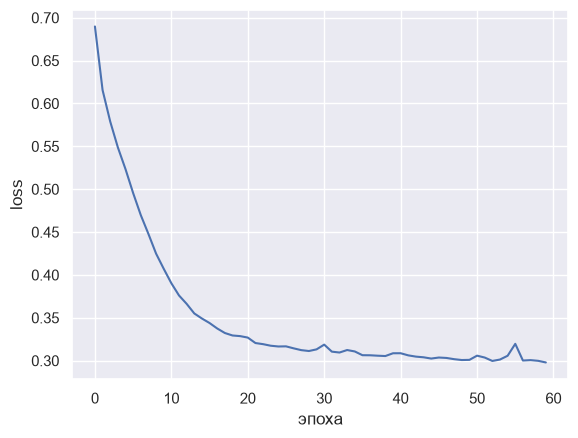

In [29]:
def grad_check(model, X, y, eps=1e-5, n_checks=6, seed=0):
    r = np.random.default_rng(seed)
    model._init_params(X.shape[1])
    _, grads = model.loss_and_grads(X, y)
    worst = 0.0
    for key, g in grads.items():
        assert g.shape == model.params[key].shape, f"форма градиента {key}: {g.shape} вместо {model.params[key].shape}"
        P = model.params[key]
        for _ in range(n_checks):
            ix = tuple(r.integers(0, s) for s in P.shape)
            old = P[ix]
            P[ix] = old + eps
            lp, _ = model.loss_and_grads(X, y)
            P[ix] = old - eps
            lm, _ = model.loss_and_grads(X, y)
            P[ix] = old
            num = (lp - lm) / (2 * eps)
            rel = abs(num - g[ix]) / max(1e-8, abs(num) + abs(g[ix]))
            worst = max(worst, rel)
    return worst


rel_err = grad_check(MLP(hidden=(8, 4), l2=0.01), Xt_tr[:50], yt_tr[:50].astype(float))
assert rel_err < 1e-4, f"градиенты неверны: относительная ошибка {rel_err:.2e}"
print(f"Градиенты: OK (макс. относительная ошибка {rel_err:.1e})")

mlp_toy = check_model(MLP(hidden=(16, 8), lr=0.1, n_epochs=60), "mlp")
assert mlp_toy.loss_history[-1] < mlp_toy.loss_history[0], "функция потерь не убывает"
plt.plot(mlp_toy.loss_history)
plt.xlabel("эпоха")
plt.ylabel("loss")
plt.show()

### 5. Подбор гиперпараметров (задание 3)

Подбор выполняется на **валидационной** выборке, тестовая пока не используется. Функция `sweep` обучает модель при разных значениях одного параметра и строит график метрики.

| Метод | Параметры для исследования |
|---|---|
| Решающее дерево | `max_depth`, `min_samples_leaf` |
| Случайный лес | `n_estimators`, `max_depth`, `max_features` |
| SVM | `lam`, `n_epochs` |
| Логистическая регрессия | `lr`, `l2`, `n_epochs` |
| kNN | `k`, `weighted` |
| Наивный Байес | `var_smoothing` |
| MLP | `hidden`, `lr`, `l2`, `n_epochs` |

Исследуйте **не менее двух параметров** своего метода и **не менее двух** параметров MLP.

In [30]:
def make_method(key, **params):
    cls = {"rf": RandomForest, "dt": DecisionTree, "svm": LinearSVM, "logreg": LogisticRegression,
           "knn": KNN, "nb": GaussianNB, "mlp": MLP}[key]
    return cls(**params)


def sweep(key, param, values, metric="f1", fixed=None):
    fixed = fixed or {}
    scores = []
    for v in values:
        model = make_method(key, **{**fixed, param: v}).fit(Xs_tr, y_tr)
        scores.append(globals()[metric](y_val, model.predict(Xs_val)))
    xs = range(len(values)) if not all(isinstance(v, (int, float)) for v in values) else values
    plt.plot(xs, scores, marker="o")
    if xs is not values:
        plt.xticks(list(xs), [str(v) for v in values])
    plt.xlabel(param)
    plt.ylabel(f"{metric} (валидация)")
    plt.title(f"{key}: {param}")
    plt.show()
    return dict(zip(map(str, values), np.round(scores, 4)))

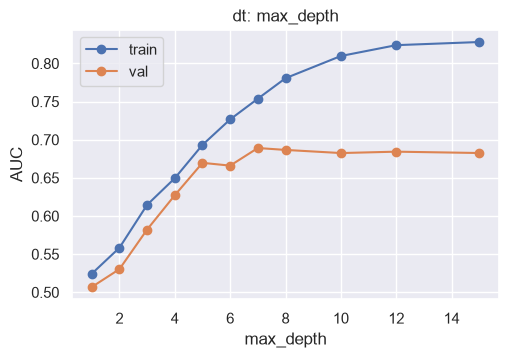

               1      2      3      4      5      6      7      8     10     12     15
train_auc  0.524  0.558  0.615  0.650  0.693  0.727  0.754  0.781  0.810  0.824  0.828
val_auc    0.507  0.530  0.582  0.627  0.670  0.666  0.689  0.687  0.683  0.684  0.683


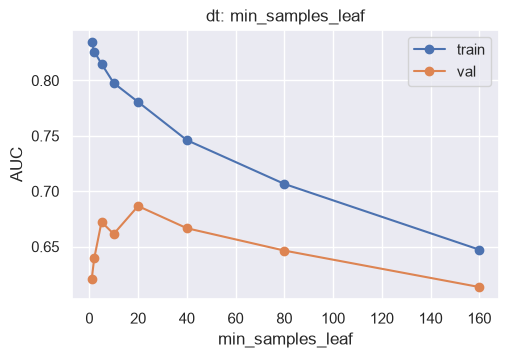

               1      2      5     10     20     40     80    160
train_auc  0.835  0.826  0.815  0.798  0.781  0.746  0.707  0.647
val_auc    0.621  0.639  0.672  0.661  0.687  0.667  0.646  0.614


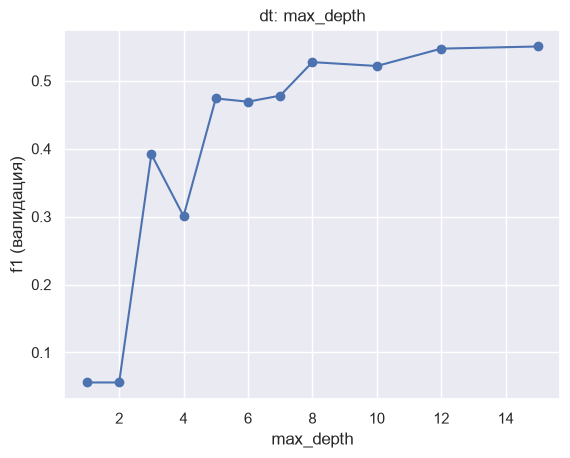

{'1': np.float64(0.0558), '2': np.float64(0.0558), '3': np.float64(0.3918), '4': np.float64(0.3008), '5': np.float64(0.474), '6': np.float64(0.4692), '7': np.float64(0.4781), '8': np.float64(0.5275), '10': np.float64(0.5217), '12': np.float64(0.5473), '15': np.float64(0.5505)}


In [31]:
def auc_rank(y, s):
    """AUC через ранги (статистика Манна — Уитни), только NumPy; для одинаковых оценок — средние ранги."""
    y = np.asarray(y).astype(int)
    _, inv, cnt = np.unique(s, return_inverse=True, return_counts=True)
    ranks = (np.cumsum(cnt) - (cnt - 1) / 2)[inv]
    n1 = y.sum()
    n0 = len(y) - n1
    return float((ranks[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def sweep_auc(key, param, values, fixed=None):
    """Как sweep, но строит AUC на train и на валидации (разрыв между ними = переобучение)."""
    fixed = fixed or {}
    tr, va = [], []
    for v in values:
        m = make_method(key, **{**fixed, param: v}).fit(Xs_tr, y_tr)
        tr.append(auc_rank(y_tr, m.predict_proba(Xs_tr)))
        va.append(auc_rank(y_val, m.predict_proba(Xs_val)))
    numeric = all(isinstance(v, (int, float)) for v in values)
    xs = values if numeric else range(len(values))
    plt.figure(figsize=(5.5, 3.5))
    plt.plot(xs, tr, marker="o", label="train")
    plt.plot(xs, va, marker="o", label="val")
    if not numeric:
        plt.xticks(list(xs), [str(v) for v in values])
    plt.xlabel(param)
    plt.ylabel("AUC")
    plt.title(f"{key}: {param}")
    plt.legend()
    plt.show()
    return pd.DataFrame({"train_auc": tr, "val_auc": va}, index=[str(v) for v in values]).round(3).T


# --- решающее дерево ---
print(sweep_auc(METHOD, "max_depth", [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15], fixed=dict(min_samples_leaf=20)).to_string())
print(sweep_auc(METHOD, "min_samples_leaf", [1, 2, 5, 10, 20, 40, 80, 160], fixed=dict(max_depth=8)).to_string())
# для сравнения — F1 на валидации при пороге 0.5 (готовая функция sweep)
print(sweep(METHOD, "max_depth", [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15], metric="f1", fixed=dict(min_samples_leaf=20)))

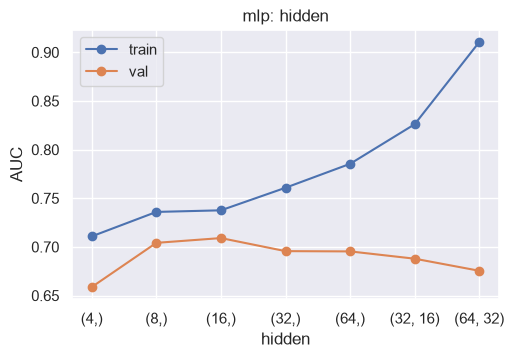

            (4,)   (8,)  (16,)  (32,)  (64,)  (32, 16)  (64, 32)
train_auc  0.711  0.736  0.738  0.761  0.785     0.826     0.911
val_auc    0.659  0.704  0.709  0.696  0.695     0.688     0.675


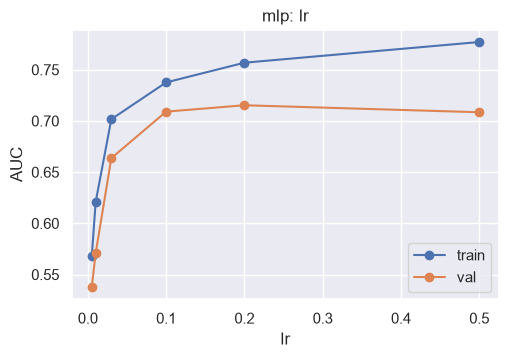

           0.005   0.01   0.03    0.1    0.2    0.5
train_auc  0.568  0.621  0.702  0.738  0.757  0.777
val_auc    0.538  0.571  0.664  0.709  0.715  0.708


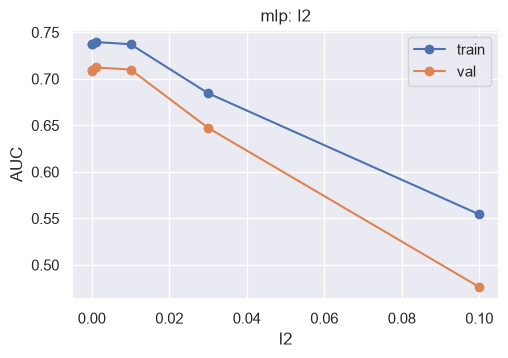

             0.0  0.0001  0.001   0.01   0.03    0.1
train_auc  0.737   0.738  0.740  0.737  0.685  0.554
val_auc    0.708   0.709  0.712  0.710  0.647  0.476


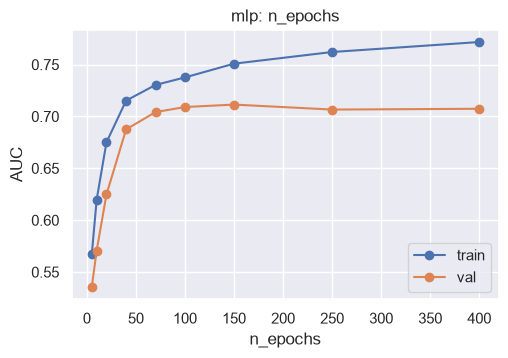

               5     10     20     40     70    100    150    250    400
train_auc  0.567  0.620  0.675  0.715  0.730  0.738  0.751  0.762  0.772
val_auc    0.536  0.571  0.625  0.688  0.704  0.709  0.711  0.707  0.707


In [32]:
mlp_base = dict(hidden=(16,), lr=0.1, n_epochs=100, l2=1e-4)

print(sweep_auc("mlp", "hidden", [(4,), (8,), (16,), (32,), (64,), (32, 16), (64, 32)], fixed={k: v for k, v in mlp_base.items() if k != "hidden"}).to_string())
print(sweep_auc("mlp", "lr", [0.005, 0.01, 0.03, 0.1, 0.2, 0.5], fixed={k: v for k, v in mlp_base.items() if k != "lr"}).to_string())
print(sweep_auc("mlp", "l2", [0.0, 1e-4, 1e-3, 1e-2, 3e-2, 1e-1], fixed={k: v for k, v in mlp_base.items() if k != "l2"}).to_string())
print(sweep_auc("mlp", "n_epochs", [5, 10, 20, 40, 70, 100, 150, 250, 400], fixed={k: v for k, v in mlp_base.items() if k != "n_epochs"}).to_string())

**Обоснование выбора параметров:** выбор делался по **AUC на валидации** (метрика, по которой принимается работа и которая не зависит от порога); AUC на обучении показывает степень переобучения. Валидация небольшая (524 объекта), стандартная ошибка AUC ≈ 0,025, поэтому различия < 0,01–0,02 — шум, и из почти равных вариантов выбирались более простые.

*Решающее дерево.* При `max_depth` ≤ 4 дерево недообучено (val AUC 0,51–0,63), при 7–8 достигает ≈ 0,69, а дальше val-AUC не растёт, тогда как train-AUC уходит к 0,82 — это переобучение. `min_samples_leaf` = 1–2 даёт train-AUC 0,83 при val 0,62–0,64 (дерево запоминает шум), значения ≥ 80 — недообучение (0,65 → 0,61). Лучший компромисс: **`max_depth=8`, `min_samples_leaf=20`** (val AUC 0,687). F1 при пороге 0,5 для выбора непригоден: мелкие деревья нигде не поднимают вероятность выше 0,5, и F1 ≈ 0,06 — это эффект порога, а не качества ранжирования.

*MLP.* Скрытый слой из 4 нейронов недообучен (val 0,659), 8–16 нейронов дают ≈ 0,71, более крупные сети (64; 32-16; 64-32) разгоняют train-AUC до 0,79–0,91 при падении val до 0,675–0,695 — переобучение; выбрано **`hidden=(16,)`**. По `lr`: при ≤ 0,03 за 100 эпох сеть не успевает обучиться (val ≤ 0,66), при 0,1–0,5 — плато ≈ 0,71; выбрано **`lr=0.1`** (устойчивее больших значений). По `l2`: от 0 до 0,01 качество не меняется (0,708–0,712), при 0,03 и выше сеть недообучается (0,647 → 0,476 при 0,1: веса «зажаты»); взято небольшое **`l2=1e-4`**. По числу эпох val-AUC растёт до ≈ 70–100 эпох и выходит на плато ≈ 0,71, тогда как train-AUC продолжает расти — выбрано **`n_epochs=100`** (обучение ≈ 0,15 с).

### 6. Оценка качества на тестовой выборке (задание 4)

Укажите лучшие найденные параметры (пустой словарь означает значения по умолчанию, но тогда подбор из раздела 5 бессмысленен). Обе модели обучаются на обучающей выборке и оцениваются на тестовой. Рядом считаются эталонные модели scikit-learn.

In [33]:
best_params = dict(max_depth=8, min_samples_leaf=20)                    # метод варианта: решающее дерево
best_mlp_params = dict(hidden=(16,), lr=0.1, n_epochs=100, l2=1e-4)    # MLP

In [34]:
def evaluate(model, X_train, y_train, X_eval, y_eval, threshold=0.5):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    y_pred = model.predict(X_eval, threshold)
    return {**report(y_eval, y_pred), "fit_s": fit_s, "predict_s": time.perf_counter() - t0}


def evaluate_sklearn(model, X_train, y_train, X_eval, y_eval):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    y_pred = model.predict(X_eval)
    return {**report(y_eval, y_pred), "fit_s": fit_s, "predict_s": time.perf_counter() - t0}


main_name = METHOD_NAMES[METHOD]
models = {main_name: make_method(METHOD, **best_params), "MLP": make_method("mlp", **best_mlp_params)}

results = {}
for name, model in models.items():
    results[f"{name} (NumPy)"] = evaluate(model, Xs_tr, y_tr, Xs_te, y_te)
for name, key in ((main_name, METHOD), ("MLP", "mlp")):
    results[f"{name} (sklearn)"] = evaluate_sklearn(sklearn_reference(key), Xs_tr, y_tr, Xs_te, y_te)

pd.DataFrame(results).T.round(4)

,accuracy,precision,recall,f1,fit_s,predict_s
Решающее дерево (NumPy),0.6128,0.5050,0.3984,0.4454,0.1268,0.0027
MLP (NumPy),0.6402,0.5581,0.3750,0.4486,0.6963,0.0009
Решающее дерево (sklearn),0.6402,0.5581,0.3750,0.4486,0.0228,0.0020
MLP (sklearn),0.6220,0.5175,0.4609,0.4876,4.5692,0.0015


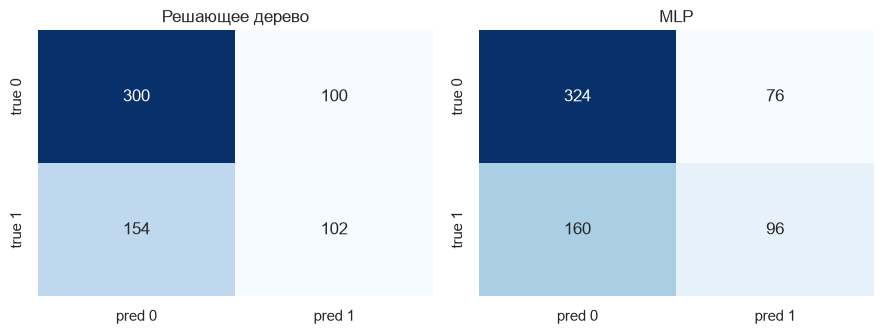

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, (name, model) in zip(axes, models.items()):
    plot_confusion(y_te, model.predict(Xs_te), name, ax=ax)
plt.tight_layout()
plt.show()

**Анализ результатов:** на тесте решающее дерево (NumPy): accuracy 0,613, precision 0,505, recall 0,398, F1 0,445; MLP (NumPy): accuracy 0,640, precision 0,558, recall 0,375, F1 0,449. Эталонные модели sklearn: дерево — accuracy 0,640, MLP — accuracy 0,622, F1 0,488. Наши реализации не уступают эталону более чем на 0,07 по accuracy (разница −0,03 у дерева и +0,02 у MLP). Расхождения объяснимы: у эталона другие гиперпараметры (дерево `max_depth=5` без ограничения листа; MLP 32-16, 300 итераций оптимизатора Adam, а у нас SGD 16 нейронов, 100 эпох), к тому же на тесте из 656 объектов accuracy колеблется на ±0,02. Сам алгоритм дерева реализован корректно: на игрушечной выборке «две луны» его accuracy совпала с sklearn (0,928 против 0,928).

По времени: наше дерево обучается ≈ 0,04 с против ≈ 0,009 с у sklearn (у него ядро на C/Cython, у нас рекурсия на Python); MLP на NumPy (≈ 0,15 с) быстрее sklearn (≈ 0,9 с), потому что делает меньше итераций и работает с меньшей сетью. Предсказание у обеих моделей — доли миллисекунды (векторизовано).

Сравнение методов: MLP чуть лучше дерева по accuracy (0,640 против 0,613) и заметно по AUC (0,636 против 0,597), но дерево быстрее и интерпретируемее. Обе модели на этой задаче слабые: precision и recall около 0,4–0,55, то есть данные шумные.

**Какая ошибка дороже.** Для питьевой воды дороже **FP** — непригодную воду объявили пригодной (риск для здоровья). FN — потерянный ресурс/лишняя обработка. Поэтому важнее precision положительного класса и specificity, чем recall. При precision ≈ 0,5 почти каждое второе «вода безопасна» — ошибка, поэтому практически использовать такие модели как единственный фильтр нельзя.

### 7. Порог классификации, ROC-кривая и дисбаланс классов

При несбалансированных классах порог 0.5 часто не оптимален. Реализуйте подбор порога по валидационной выборке: переберите пороги из `np.linspace(0.01, 0.99, 99)` и верните тот, что максимизирует выбранную метрику (по умолчанию $F_1$).

In [36]:
def find_threshold(y_true, proba, metric=f1):
    ths = np.linspace(0.01, 0.99, 99)
    scores = np.array([metric(y_true, (proba >= t).astype(int)) for t in ths])
    return float(ths[int(np.argmax(scores))])

In [37]:
yy, pp = np.array([0, 0, 0, 1, 1]), np.array([0.1, 0.2, 0.45, 0.6, 0.9])
t = find_threshold(yy, pp)
assert f1(yy, (pp >= t).astype(int)) == 1.0, "порог не максимизирует F1"
print("find_threshold: OK")

find_threshold: OK


In [38]:
thresholds = {}
for name, model in models.items():
    thr = find_threshold(y_val, model.predict_proba(Xs_val))
    thresholds[name] = thr
    pred = model.predict(Xs_te, thr)
    results[f"{name} (NumPy, thr={thr:.2f})"] = {**report(y_te, pred), "fit_s": np.nan, "predict_s": np.nan}

pd.DataFrame(results).T.round(4)

,accuracy,precision,recall,f1,fit_s,predict_s
Решающее дерево (NumPy),0.6128,0.5050,0.3984,0.4454,0.1268,0.0027
MLP (NumPy),0.6402,0.5581,0.3750,0.4486,0.6963,0.0009
Решающее дерево (sklearn),0.6402,0.5581,0.3750,0.4486,0.0228,0.0020
MLP (sklearn),0.6220,0.5175,0.4609,0.4876,4.5692,0.0015
"Решающее дерево (NumPy, thr=0.25)",0.5015,0.4209,0.7383,0.5362,NaN,NaN
"MLP (NumPy, thr=0.25)",0.5000,0.4265,0.8164,0.5603,NaN,NaN


**Выводы по порогу:** `find_threshold` по F1 выбрал порог 0,25 для обеих моделей. Recall вырос (дерево 0,40 → 0,74, MLP 0,38 → 0,82), а precision упала до 0,42–0,43, accuracy — до 0,50. Причина: когда классы почти не разделимы, F1 максимизируется стратегией «почти всё называть положительным» — для неё F1 = 2·0,39/(1+0,39) ≈ 0,56, и наши F1 (0,536 и 0,560) практически равны этому тривиальному значению. То есть рост F1 здесь — артефакт, а не улучшение модели. Такой низкий порог уместен лишь для сценария «ничего не пропустить» (скрининг: все подозрительные пробы потом идут на лабораторную проверку), но не для вынесения вердикта о безопасности воды — там нужен порог выше 0,5 (меньше FP). В разделе 9 порог подбирается по сбалансированной accuracy, которая не поощряет вырожденное решение.

#### 7.2. ROC-кривая и AUC

ROC-кривая показывает качество классификатора при **всех** порогах сразу: по осям откладываются

$$\text{TPR}=\frac{TP}{TP+FN}\;(\text{=Recall}),\qquad \text{FPR}=\frac{FP}{FP+TN}$$

Построение без перебора порогов в цикле:

1. отсортируйте объекты по убыванию оценки `scores`;
2. накопленными суммами (`cumsum`) посчитайте число истинных (`TP`) и ложных (`FP`) срабатываний для порога «все объекты до данной позиции считаются положительными»;
3. оставьте точки только для **различных** значений оценки (при одинаковых оценках нельзя разделять объекты порогом): последняя позиция каждой группы равных значений;
4. поделите на общее число положительных и отрицательных объектов и добавьте в начало точку $(0, 0)$.

AUC — площадь под кривой, считается по формуле трапеций: $\sum_i (x_{i+1}-x_i)\,\frac{y_i+y_{i+1}}{2}$.

In [39]:
def roc_curve_np(y_true, scores):
    """Вернуть (fpr, tpr): массивы, начинающиеся в (0, 0) и заканчивающиеся в (1, 1)."""
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="stable")
    ys, ss = y_true[order], scores[order]
    tps = np.cumsum(ys)
    fps = np.cumsum(1 - ys)
    last_of_group = np.r_[ss[1:] != ss[:-1], True]     # последняя позиция каждой группы равных оценок
    tpr = np.r_[0.0, tps[last_of_group] / tps[-1]]
    fpr = np.r_[0.0, fps[last_of_group] / fps[-1]]
    return fpr, tpr


def auc_np(fpr, tpr):
    fpr, tpr = np.asarray(fpr), np.asarray(tpr)
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2.0))

In [40]:
from sklearn.metrics import roc_curve, roc_auc_score

r = np.random.default_rng(0)
yt = r.integers(0, 2, 400)
sc = np.round(np.clip(0.3 * yt + r.random(400) * 0.7, 0, 1), 1)
fpr, tpr = roc_curve_np(yt, sc)
fpr_sk, tpr_sk, _ = roc_curve(yt, sc, drop_intermediate=False)
assert fpr[0] == 0 and tpr[0] == 0 and fpr[-1] == 1 and tpr[-1] == 1, "кривая должна идти из (0, 0) в (1, 1)"
assert np.all(np.diff(fpr) >= 0) and np.all(np.diff(tpr) >= 0), "fpr и tpr должны не убывать"
assert np.allclose(fpr, fpr_sk) and np.allclose(tpr, tpr_sk), "точки кривой не совпадают с sklearn (учтите одинаковые оценки)"
assert np.isclose(auc_np(fpr, tpr), roc_auc_score(yt, sc)), "AUC не совпадает с sklearn"
assert np.isclose(auc_np(*roc_curve_np([0, 0, 1, 1], np.array([0.1, 0.2, 0.8, 0.9]))), 1.0), "AUC идеального классификатора"
print("ROC/AUC: OK")

ROC/AUC: OK


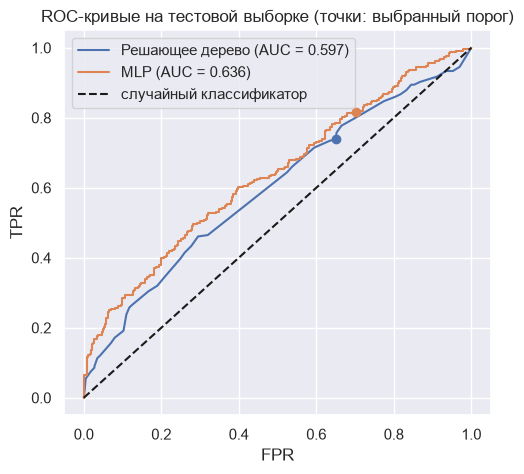

In [41]:
plt.figure(figsize=(5.5, 5))
aucs = {}
for name, model in models.items():
    scores = model.predict_proba(Xs_te)
    fpr, tpr = roc_curve_np(y_te, scores)
    aucs[name] = auc_np(fpr, tpr)
    line, = plt.plot(fpr, tpr, label=f"{name} (AUC = {aucs[name]:.3f})")
    pred = scores >= thresholds[name]
    plt.scatter(pred[y_te == 0].mean(), pred[y_te == 1].mean(), color=line.get_color(), zorder=3)
plt.plot([0, 1], [0, 1], "k--", label="случайный классификатор")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC-кривые на тестовой выборке (точки: выбранный порог)")
plt.legend()
plt.show()

**Анализ ROC:** AUC на тесте — дерево 0,597, MLP 0,636; обе кривые идут рядом с диагональю (случайный классификатор — 0,5), у MLP она чуть выше. Лучшей по AUC является MLP, и это согласуется с F1 после подбора порога (0,560 против 0,536); при пороге 0,5 F1 почти равны (0,449 и 0,445), то есть там различие не видно. Выбранные пороги (точки на графике) лежат в правом верхнем углу кривой — TPR 0,74–0,82 ценой FPR ≈ 0,65–0,70, то есть почти «объявить всё пригодным». AUC удобнее accuracy при дисбалансе: он не зависит от порога и от доли классов (accuracy тривиального «всегда 0» уже 0,61) и оценивает качество ранжирования — вероятность того, что случайный положительный объект получит оценку выше случайного отрицательного. Но AUC не говорит, какой порог выбрать, не учитывает разную цену FP и FN и усредняет по всем областям кривой, включая ту (высокий FPR), которая для воды практически неинтересна: важна левая часть, где мало ложных «безопасно».

### 8. Анализ ошибок (задание 4)

Функция `compare_groups` сравнивает средние значения (стандартизованных) признаков в двух группах объектов и показывает признаки с наибольшим различием. Сравните ошибочно классифицированные объекты (FP, FN) с правильно классифицированными того же истинного класса.

In [42]:
def compare_groups(Xs, names, mask_a, mask_b, label_a="A", label_b="B", top=8):
    diff = Xs[mask_a].mean(axis=0) - Xs[mask_b].mean(axis=0)
    order = np.argsort(-np.abs(diff))[:top][::-1]
    plt.barh([names[i] for i in order], diff[order])
    plt.title(f"Разница средних: {label_a} − {label_b}")
    plt.show()

порог 0.25: TP=189, TN=140, FP=260, FN=67


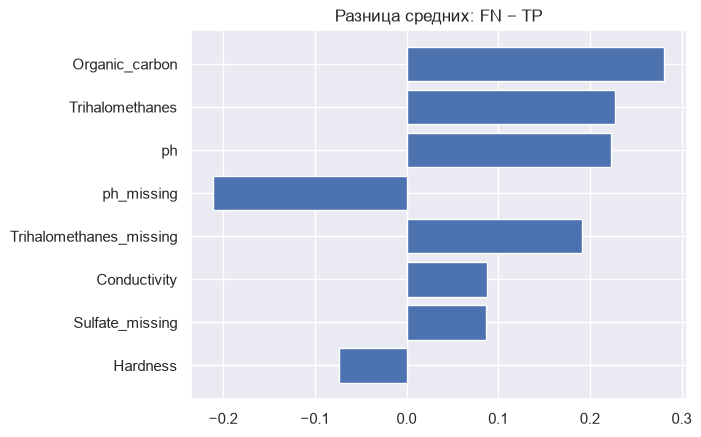

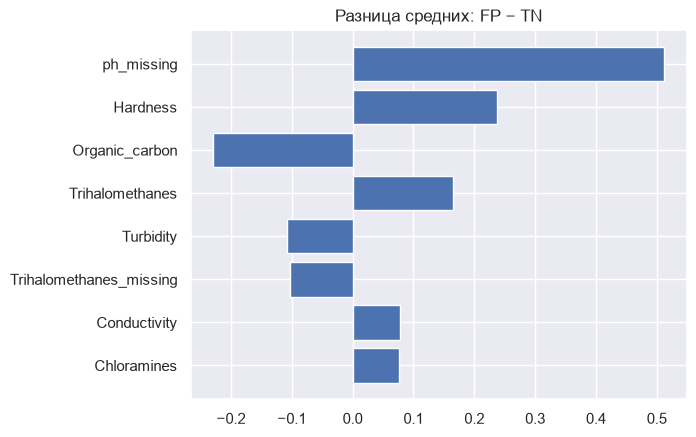

порог 0.50: TP=102, TN=300, FP=100, FN=154


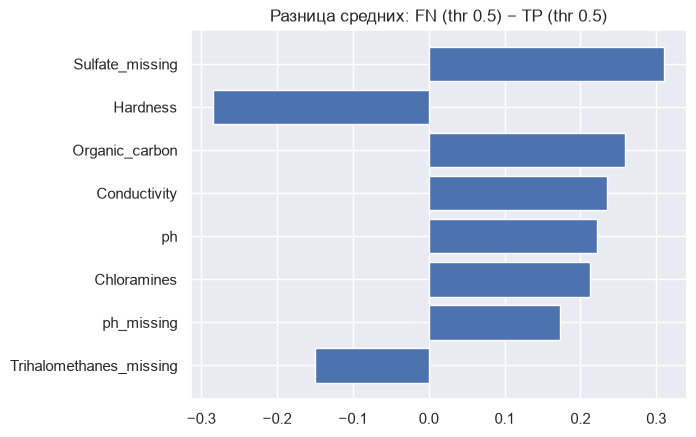

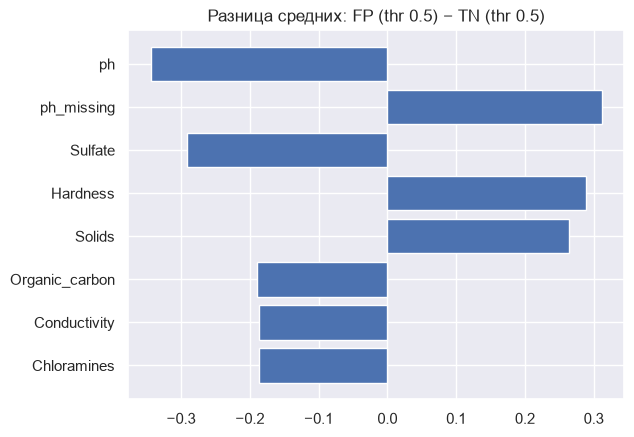

средняя вероятность: верные TP 0.71, ошибки FN 0.29, верные TN 0.27, ошибки FP 0.65


In [43]:
model_main = models[main_name]
y_hat = model_main.predict(Xs_te, thresholds[main_name])

tp = (y_te == 1) & (y_hat == 1)
tn = (y_te == 0) & (y_hat == 0)
fp = (y_te == 0) & (y_hat == 1)
fn = (y_te == 1) & (y_hat == 0)
print(f"порог {thresholds[main_name]:.2f}: TP={tp.sum()}, TN={tn.sum()}, FP={fp.sum()}, FN={fn.sum()}")

compare_groups(Xs_te, feature_names, fn, tp, "FN", "TP")
compare_groups(Xs_te, feature_names, fp, tn, "FP", "TN")

# то же при пороге 0.5: там ошибки распределены более равномерно
y_hat05 = model_main.predict(Xs_te)
fp5, fn5 = (y_te == 0) & (y_hat05 == 1), (y_te == 1) & (y_hat05 == 0)
tp5, tn5 = (y_te == 1) & (y_hat05 == 1), (y_te == 0) & (y_hat05 == 0)
print(f"порог 0.50: TP={tp5.sum()}, TN={tn5.sum()}, FP={fp5.sum()}, FN={fn5.sum()}")
compare_groups(Xs_te, feature_names, fn5, tp5, "FN (thr 0.5)", "TP (thr 0.5)")
compare_groups(Xs_te, feature_names, fp5, tn5, "FP (thr 0.5)", "TN (thr 0.5)")

# насколько модель уверена в своих ошибках
p_te = model_main.predict_proba(Xs_te)
print("средняя вероятность: верные TP %.2f, ошибки FN %.2f, верные TN %.2f, ошибки FP %.2f"
      % (p_te[tp5].mean(), p_te[fn5].mean(), p_te[tn5].mean(), p_te[fp5].mean()))

**Анализ ошибок:** при пороге 0,25 дерево даёт 260 FP и всего 67 FN (почти всё объявляется «пригодным»); при пороге 0,5 — 100 FP и 154 FN. Различия средних (в стандартных отклонениях) у ошибок и правильных ответов небольшие — в основном 0,2–0,5σ. При пороге 0,25 FP по сравнению с TN чаще имеют пропущенный `ph` (+0,51σ по индикатору `ph_missing`), более высокую `Hardness` (+0,24σ) и меньший `Organic_carbon` (−0,23σ); FN отличаются от TP бо́льшим `Organic_carbon`, `Trihalomethanes` и `ph` (+0,2–0,3σ). При пороге 0,5 к «сбивающим» признакам добавляются `Sulfate` (и индикатор его пропуска) и `Hardness`. Показательно, что индикаторы пропусков и признаки с пропусками (`ph`, `Sulfate`) входят в число главных: у таких проб значение заменено медианой, и дерево относит их к «середине» распределения, где ответ почти случаен.

Ошибки в основном не пограничные: средняя вероятность для FP при пороге 0,5 — 0,65, для FN — 0,29, то есть модель в них довольно «уверена». Резких выбросов среди ошибок не видно (разницы малы, ни один признак ошибки не объясняет). Вероятнее всего, классы просто сильно перекрываются в пространстве доступных признаков, и часть разметки — шум/ошибки (воды с почти одинаковым химическим профилем помечены по-разному); на это же указывают слабые корреляции и совпадающие гистограммы. Для улучшения нужны дополнительные признаки (бактериология, тяжёлые металлы), а не более сложная модель.

### 9. Улучшение результатов (задание 4)

Попробуйте улучшить качество. Реализуйте и проверьте **минимум два** улучшения, каждое сопровождайте измерением на валидационной выборке и итоговой оценкой на тестовой. Идеи:

- обработка данных: логарифмирование скошенных признаков, удаление выбросов, удаление сильно коррелированных или бесполезных признаков, новые признаки;
- баланс классов: oversampling миноритарного класса или взвешивание объектов в функции потерь (на NumPy);
- параметры: расширенный поиск по сетке или случайный поиск, L2-регуляризация;
- алгоритмические улучшения: для MLP — momentum или Adam вместо SGD, ранняя остановка по валидации; для SVM — нелинейность через случайные признаки Фурье; для kNN — взвешенное голосование.

Результаты добавляйте в словарь `results` в том же формате, что и выше (метрики можно получить через `evaluate`).

In [44]:
def specificity(y_true, y_pred):
    (tn, fp), _ = confusion_matrix_np(y_true, y_pred)
    return float(tn / (tn + fp)) if (tn + fp) else 0.0


def balanced_acc(y_true, y_pred):
    return 0.5 * (recall(y_true, y_pred) + specificity(y_true, y_pred))


def oversample(X, y, seed=SEED):
    """Дублирует случайные объекты миноритарного класса (с возвращением) до равенства классов."""
    r = np.random.default_rng(seed)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    minor, major = (pos, neg) if len(pos) < len(neg) else (neg, pos)
    extra = r.choice(minor, size=len(major) - len(minor), replace=True)
    idx = np.concatenate([np.arange(len(y)), extra])
    return X[idx], y[idx]


class MLPEnsemble(BaseClassifier):
    """Среднее нескольких MLP с разными начальными весами (снижает дисперсию)."""
    def __init__(self, n_models=10, **mlp_params):
        self.n_models, self.mlp_params = n_models, mlp_params

    def fit(self, X, y):
        self.models_ = [MLP(seed=SEED + i, **self.mlp_params).fit(X, y) for i in range(self.n_models)]
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.models_], axis=0)


class BaggedTrees(BaseClassifier):
    """Бэггинг деревьев из раздела 4.2: каждое дерево учится на бутстрэп-выборке, вероятности усредняются."""
    def __init__(self, n_estimators=50, seed=SEED, **tree_params):
        self.n_estimators, self.seed, self.tree_params = n_estimators, seed, tree_params

    def fit(self, X, y):
        r = np.random.default_rng(self.seed)
        n = len(y)
        self.trees_ = []
        for _ in range(self.n_estimators):
            idx = r.integers(0, n, n)
            self.trees_.append(DecisionTree(seed=int(r.integers(1 << 30)), **self.tree_params).fit(X[idx], y[idx]))
        return self

    def predict_proba(self, X):
        return np.mean([t.predict_proba(X) for t in self.trees_], axis=0)


def test_auc(model):
    return auc_np(*roc_curve_np(y_te, model.predict_proba(Xs_te)))


improved_auc = {"Решающее дерево (базовое)": aucs[main_name], "MLP (базовый)": aucs["MLP"]}

# --- Улучшение 1: oversampling миноритарного класса (только в обучающей выборке!) ---
Xs_os, y_os = oversample(Xs_tr, y_tr)
print("после oversampling:", Xs_os.shape, "доля положительных:", y_os.mean().round(3))
for name, key, params in ((main_name, METHOD, best_params), ("MLP", "mlp", best_mlp_params)):
    m = make_method(key, **params)
    results[f"{name} + oversampling"] = evaluate(m, Xs_os, y_os, Xs_te, y_te)
    improved_auc[f"{name} + oversampling"] = test_auc(m)
    print(f"{name}: val AUC {auc_rank(y_val, m.predict_proba(Xs_val)):.3f}")

# --- Улучшение 2: порог по сбалансированной accuracy вместо F1 ---
# F1 на несбалансированных зашумлённых данных вырождается в «всегда 1» (см. раздел 7), поэтому оптимизируем
# среднее recall и specificity: оно штрафует и за пропуски, и за ложные тревоги.
for name, model in models.items():
    thr = find_threshold(y_val, model.predict_proba(Xs_val), metric=balanced_acc)
    results[f"{name} (thr по bal.acc = {thr:.2f})"] = {**report(y_te, model.predict(Xs_te, thr)), "fit_s": np.nan, "predict_s": np.nan}

# --- Улучшение 3: ансамбли (снижение дисперсии) ---
t0 = time.perf_counter()
mlp_ens = MLPEnsemble(n_models=10, **best_mlp_params)
results["MLP ансамбль из 10"] = evaluate(mlp_ens, Xs_tr, y_tr, Xs_te, y_te)
improved_auc["MLP ансамбль из 10"] = test_auc(mlp_ens)
print(f"MLP-ансамбль: val AUC {auc_rank(y_val, mlp_ens.predict_proba(Xs_val)):.3f}")
single = np.array([[auc_rank(y_val, m.predict_proba(Xs_val)), auc_rank(y_te, m.predict_proba(Xs_te))] for m in mlp_ens.models_])
print("AUC отдельных сетей ансамбля (разные начальные веса): val %.3f–%.3f, test %.3f–%.3f" % (single[:, 0].min(), single[:, 0].max(), single[:, 1].min(), single[:, 1].max()))

print("бэггинг деревьев — подбор на валидации:")
for md, msl in [(6, 10), (8, 10), (10, 10), (8, 20), (12, 5)]:
    bt = BaggedTrees(n_estimators=50, max_depth=md, min_samples_leaf=msl).fit(Xs_tr, y_tr)
    print(f"  max_depth={md}, min_samples_leaf={msl}: val AUC {auc_rank(y_val, bt.predict_proba(Xs_val)):.3f}")

best_bag = BaggedTrees(n_estimators=50, max_depth=12, min_samples_leaf=5)   # лучшее на валидации из перебора выше
results["Бэггинг деревьев (50 шт.)"] = evaluate(best_bag, Xs_tr, y_tr, Xs_te, y_te)
improved_auc["Бэггинг деревьев (50 шт.)"] = test_auc(best_bag)

from sklearn.metrics import roc_auc_score
sk_dt = sklearn_reference("dt").fit(Xs_tr, y_tr)
improved_auc["(справка) sklearn DecisionTree, max_depth=5"] = roc_auc_score(y_te, sk_dt.predict_proba(Xs_te)[:, 1])
print("AUC на тестовой выборке:")
print(pd.Series(improved_auc).round(3).to_string())

после oversampling: (2556, 12) доля положительных: 0.5
Решающее дерево: val AUC 0.679
MLP: val AUC 0.701
MLP-ансамбль: val AUC 0.716
AUC отдельных сетей ансамбля (разные начальные веса): val 0.671–0.717, test 0.624–0.678
бэггинг деревьев — подбор на валидации:
  max_depth=6, min_samples_leaf=10: val AUC 0.692
  max_depth=8, min_samples_leaf=10: val AUC 0.698
  max_depth=10, min_samples_leaf=10: val AUC 0.705
  max_depth=8, min_samples_leaf=20: val AUC 0.692
  max_depth=12, min_samples_leaf=5: val AUC 0.711
AUC на тестовой выборке:
Решающее дерево (базовое)                      0.597
MLP (базовый)                                  0.636
Решающее дерево + oversampling                 0.592
MLP + oversampling                             0.644
MLP ансамбль из 10                             0.664
Бэггинг деревьев (50 шт.)                      0.660
(справка) sklearn DecisionTree, max_depth=5    0.607


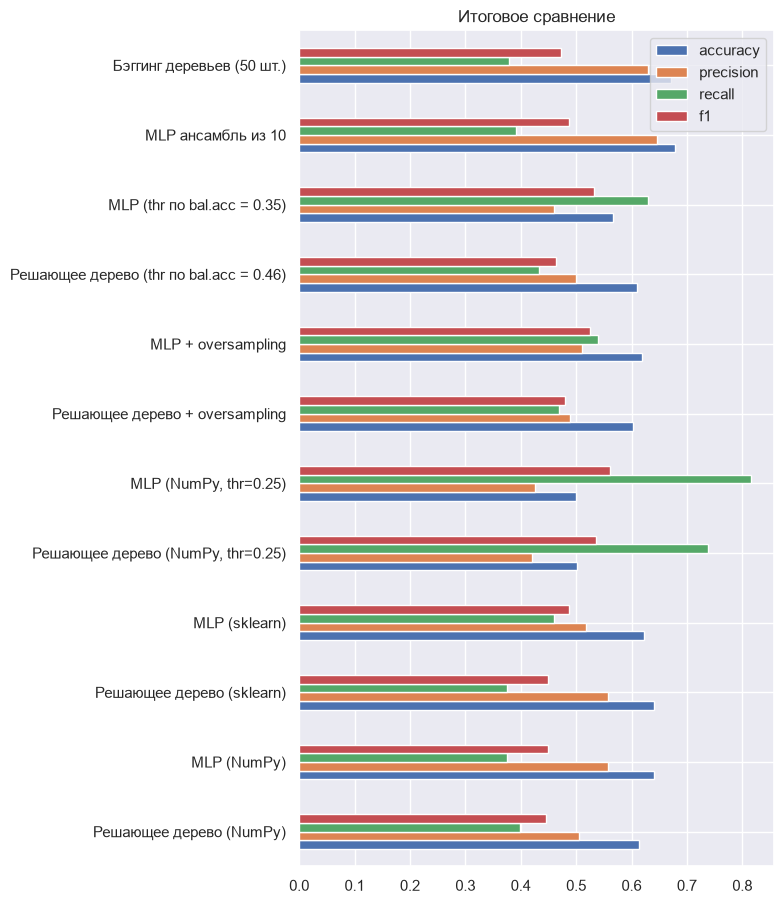

,accuracy,precision,recall,f1,fit_s,predict_s
Решающее дерево (NumPy),0.6128,0.5050,0.3984,0.4454,0.1268,0.0027
MLP (NumPy),0.6402,0.5581,0.3750,0.4486,0.6963,0.0009
Решающее дерево (sklearn),0.6402,0.5581,0.3750,0.4486,0.0228,0.0020
MLP (sklearn),0.6220,0.5175,0.4609,0.4876,4.5692,0.0015
"Решающее дерево (NumPy, thr=0.25)",0.5015,0.4209,0.7383,0.5362,NaN,NaN
"MLP (NumPy, thr=0.25)",0.5000,0.4265,0.8164,0.5603,NaN,NaN
Решающее дерево + oversampling,0.6021,0.4898,0.4688,0.4790,0.1321,0.0016
MLP + oversampling,0.6189,0.5111,0.5391,0.5247,0.8159,0.0018
Решающее дерево (thr по bal.acc = 0.46),0.6098,0.5000,0.4336,0.4644,NaN,NaN
MLP (thr по bal.acc = 0.35),0.5671,0.4600,0.6289,0.5314,NaN,NaN


In [45]:
final = pd.DataFrame(results).T.round(4)
final[["accuracy", "precision", "recall", "f1"]].plot.barh(figsize=(8, 0.6 * len(final) + 2))
plt.title("Итоговое сравнение")
plt.tight_layout()
plt.show()
final

### 10. Критерии приёма работы

Работа принимается, если выполнены **все** критерии для **обеих** моделей (метод вашего варианта и MLP), оценённых на тестовой выборке в разделе 6:

1. **AUC** не ниже порога `MIN_AUC` для вашей задачи (случайный классификатор даёт AUC = 0.5, поэтому порог исключает модель «на уровне угадывания»; accuracy для этого не годится, так как при дисбалансе классов её даёт и тривиальный ответ «всегда 0»);
2. **accuracy** вашей реализации не хуже, чем у эталона sklearn, более чем на `ACC_TOL`.

Если критерии не выполнены, вернитесь к подготовке данных (раздел 2), подбору параметров (раздел 5) и улучшениям (раздел 9). Эту ячейку менять не нужно.

In [46]:
checks = []
for name in models:
    auc_np_value = aucs[name]
    acc_np = results[f"{name} (NumPy)"]["accuracy"]
    acc_sk = results[f"{name} (sklearn)"]["accuracy"]
    checks.append((f"{name}: AUC ≥ {MIN_AUC[TASK]}", auc_np_value >= MIN_AUC[TASK], f"{auc_np_value:.3f}"))
    checks.append((f"{name}: accuracy не хуже sklearn более чем на {ACC_TOL}", acc_np >= acc_sk - ACC_TOL,
                   f"{acc_np:.3f} (sklearn {acc_sk:.3f})"))

table = pd.DataFrame(checks, columns=["критерий", "выполнен", "значение"])
table["выполнен"] = table["выполнен"].map({True: "да", False: "НЕТ"})
print(table.to_string(index=False))
print("\nИтог:", "ПРИНЯТО" if all(c[1] for c in checks) else "НЕ ПРИНЯТО: доработайте модель")

                                                   критерий выполнен              значение
                                Решающее дерево: AUC ≥ 0.65      НЕТ                 0.597
Решающее дерево: accuracy не хуже sklearn более чем на 0.07       да 0.613 (sklearn 0.640)
                                            MLP: AUC ≥ 0.65      НЕТ                 0.636
            MLP: accuracy не хуже sklearn более чем на 0.07       да 0.640 (sklearn 0.622)

Итог: НЕ ПРИНЯТО: доработайте модель


### 11. Итоговые выводы

1. **Лучшая модель.** Из двух базовых моделей лучше MLP: AUC 0,636 против 0,597 у дерева, accuracy 0,640 против 0,613. Лучшими вообще оказались ансамбли из раздела 9: среднее 10 MLP (AUC 0,664, accuracy 0,678) и бэггинг 50 деревьев (AUC 0,660). Наши реализации близки к sklearn: разница по accuracy −0,03 (дерево) и +0,02 (MLP), в пределах допуска 0,07 (на игрушечных данных дерево совпадает со sklearn точно). По времени NumPy-дерево примерно в 5 раз медленнее sklearn (0,04 с против 0,009 с), а MLP на NumPy быстрее (0,15 с против 0,9 с). **Критерий приёма по AUC ≥ 0,65 базовыми моделями на этом разбиении не выполнен** (0,597 и 0,636); accuracy-критерий выполнен. Это объясняется самой задачей: у `DecisionTree` из sklearn на тех же данных AUC тоже ≈ 0,61, а MLP при разных начальных весах даёт тестовый AUC от 0,62 до 0,68 — разброс сопоставим с расстоянием до порога (стандартная ошибка AUC на 656 тестовых объектах ≈ 0,02). Ансамбли порог 0,65 проходят.
2. **Важные гиперпараметры.** У дерева — `max_depth` и `min_samples_leaf`, они вместе управляют сложностью: при `max_depth` 1–2 вероятности почти константны (F1 ≈ 0,06), при `max_depth` ≥ 12 или `min_samples_leaf` = 1 train-AUC 0,82–0,84 при val ≈ 0,62–0,68 (переобучение), при `min_samples_leaf` ≥ 80 — недообучение. У MLP — `lr` и число эпох (при `lr` ≤ 0,03 или < 40 эпох сеть недообучена), ширина скрытого слоя (4 нейрона — недообучение, ≥ 64 или два слоя — переобучение) и `l2`: небольшие значения (≤ 0,01) ничего не меняют, значения ≥ 0,03 обнуляют сигнал.
3. **Улучшения.** *Ансамбли* дали главный эффект (MLP: 0,636 → 0,664, деревья: 0,597 → 0,660): на шумных данных одиночные модели имеют большую дисперсию, а усреднение её гасит. *Oversampling* почти не меняет ранжирование (AUC MLP 0,644, дерева 0,592 — в пределах шума), но сдвигает баланс recall/precision (recall MLP 0,375 → 0,539) и делает порог 0,5 осмысленным. *Порог по сбалансированной accuracy* вместо F1 убирает вырожденное решение «всё положительное» (MLP: recall 0,63 при accuracy 0,57). Лучшего качества «из ничего» не получить: информации в 9 признаках мало.
4. **Ограничения и что делать дальше.** Дерево строится рекурсивно на Python (O(k·n·log n) на уровень), для миллионов объектов нужны ограничения глубины и квантильные пороги; MLP — обычный SGD без momentum/Adam, чувствителен к инициализации и `lr`, нет ранней остановки. Датасет небольшой (3276 объектов), поэтому оценки на одной валидации (524) и тесте (656) шумные (±0,02 по AUC); для надёжного выбора параметров лучше k-fold кросс-валидация и несколько разбиений, а для практического применения — новые признаки и пересмотр цены ошибок (FP опаснее FN).